Dataset shape: (108, 2)
Missing values:
 Month    0
Sales    0
dtype: int64


,Month,Sales
0,1960-01-01,6550
1,1960-02-01,8728
2,1960-03-01,12026
3,1960-04-01,14395
4,1960-05-01,14587


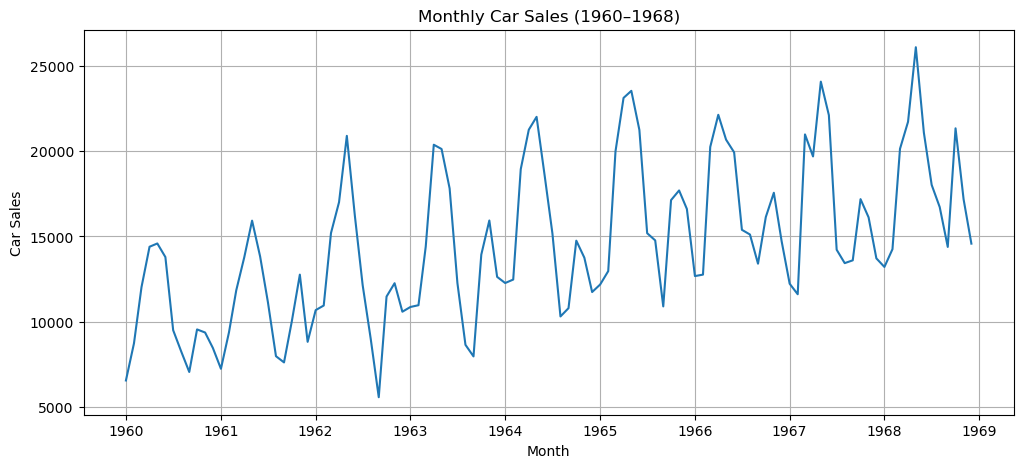

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load monthly car sales data
df = pd.read_csv("monthly-car-sales.csv")

# Convert Month to datetime and sort chronologically
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").reset_index(drop=True)

# Inspect the dataset
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
display(df.head())

# Visualize monthly car sales
plt.figure(figsize=(12, 5))
plt.plot(df["Month"], df["Sales"])
plt.title("Monthly Car Sales (1960–1968)")
plt.xlabel("Month")
plt.ylabel("Car Sales")
plt.grid(True)
plt.show()

In [2]:
# Create lag features (sales from last 6 months)
# The goal is to predict sales in month \(t\) using sales from the previous six months.
# lag_i is Sales i month ago, i from 1 to 6

# Create six lag features
for i in range(1, 7):
    df[f"lag_{i}"] = df["Sales"].shift(i)

# Remove the first six rows with unavailable lag values
df = df.dropna().reset_index(drop=True)

# Define predictors and target
feature_cols = [f"lag_{i}" for i in range(1, 7)]

X = df[feature_cols]
y = df["Sales"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(df.head())

Feature shape: (102, 6)
Target shape: (102,)


,Month,Sales,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6
0,1960-07-01,9498,13791.0,14587.0,14395.0,12026.0,8728.0,6550.0
1,1960-08-01,8251,9498.0,13791.0,14587.0,14395.0,12026.0,8728.0
2,1960-09-01,7049,8251.0,9498.0,13791.0,14587.0,14395.0,12026.0
3,1960-10-01,9545,7049.0,8251.0,9498.0,13791.0,14587.0,14395.0
4,1960-11-01,9364,9545.0,7049.0,8251.0,9498.0,13791.0,14587.0


In [3]:
# Split training and testing data: 80% training and 20% test data

# Chronological 80/20 split
split_idx = int(len(X) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training period:",
      df["Month"].iloc[0],
      "to",
      df["Month"].iloc[split_idx - 1])

print("Testing period:",
      df["Month"].iloc[split_idx],
      "to",
      df["Month"].iloc[-1])

Training observations: 81
Testing observations: 21
Training period: 1960-07-01 00:00:00 to 1967-03-01 00:00:00
Testing period: 1967-04-01 00:00:00 to 1968-12-01 00:00:00


In [4]:
# Use XGBRegressor to train the model 

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize XGBoost regression model
model = XGBRegressor(
    n_estimators=200,       # Number of boosting trees
    learning_rate=0.05,     # Learning rate
    max_depth=3,            # Maximum tree depth
    subsample=0.8,          # Fraction of observations used per tree
    colsample_bytree=0.8,   # Fraction of features used per tree
    random_state=42
)

# Train the model using historical sales
model.fit(X_train, y_train)

# Predict sales for the testing period
y_pred = model.predict(X_test)

print("Model training completed!")

Model training completed!


In [5]:
# Evaluate forecasting performance

# Calculate regression performance metrics
mae = mean_absolute_error(y_test, y_pred)  # MAE: Average absolute difference between predicted and actual monthly sales. Lower is better.
rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # RMSE: Similar to MAE, but penalizes larger prediction errors more heavily. Lower is better.
r2 = r2_score(y_test, y_pred) # R²: Measures performance relative to predicting the test-set mean. A negative R² indicates worse performance than that reference.

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

# Compare with a simple baseline:
# Predict that next month's sales equal last month's sales
baseline_pred = X_test["lag_1"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("\nNaive Baseline:")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")

MAE: 2259.27
RMSE: 2983.53
R²: 0.380

Naive Baseline:
MAE: 2970.67
RMSE: 3647.54


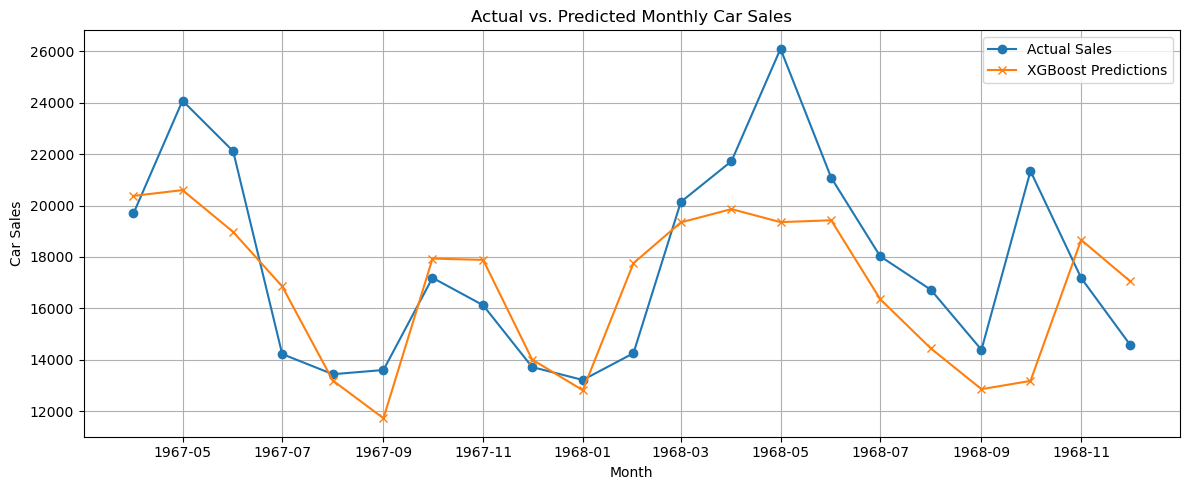

In [6]:
# Visualize actual versus predicted sales
# examine whether XGBoost captures changes in monthly sales and whether it systematically overpredicts or underpredicts certain periods.

plt.figure(figsize=(12, 5))

# Actual sales during testing period
plt.plot(
    df["Month"].iloc[split_idx:],
    y_test,
    label="Actual Sales",
    marker="o"
)

# Predicted sales
plt.plot(
    df["Month"].iloc[split_idx:],
    y_pred,
    label="XGBoost Predictions",
    marker="x"
)

plt.title("Actual vs. Predicted Monthly Car Sales")
plt.xlabel("Month")
plt.ylabel("Car Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Save the model as JSON

import os

# Create model folder if it doesn't exist
os.makedirs("model", exist_ok=True)

# Save the trained XGBoost model as JSON
model.get_booster().save_model("model/model.json")

print("Model saved successfully!")
print("File exists:", os.path.exists("model/model.json"))

Model saved successfully!
File exists: True


In [8]:
# Create the HTML form

os.makedirs("frontend", exist_ok=True)

In [9]:
%%writefile frontend/index.html

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Car Sales Forecast</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            max-width: 520px;
            margin: 50px auto;
            padding: 20px;
        }
        input {
            width: 100%;
            padding: 10px;
            margin: 6px 0 14px;
            box-sizing: border-box;
        }
        button {
            padding: 12px 20px;
            background: #2563eb;
            color: white;
            border: none;
            cursor: pointer;
        }
        #result {
            margin-top: 20px;
            font-size: 20px;
            font-weight: bold;
        }
    </style>
</head>
<body>

<h2>Next Month's Car Sales Forecast</h2>
<p>Enter sales for the previous six months, starting with the most recent month.</p>

<form id="salesForm">
    <div id="inputs"></div>
    <button type="submit">Predict Sales</button>
</form>

<div id="result"></div>

<script>
    const container = document.getElementById("inputs");

    for (let i = 1; i <= 6; i++) {
        container.innerHTML += `
            <label>Month ${i} ago:</label>
            <input type="number" id="month${i}"
                   min="0" step="any" required>
        `;
    }

    document.getElementById("salesForm").addEventListener(
        "submit", async function(event) {
            event.preventDefault();

            const sales = [];

            for (let i = 1; i <= 6; i++) {
                sales.push(
                    Number(document.getElementById(`month${i}`).value)
                );
            }

            const result = document.getElementById("result");
            result.textContent = "Calculating forecast...";

            try {
                const response = await fetch("/predict", {
                    method: "POST",
                    headers: {
                        "Content-Type": "application/json"
                    },
                    body: JSON.stringify({ sales: sales })
                });

                const data = await response.json();

                if (!response.ok) {
                    throw new Error(
                        JSON.stringify(data.detail || data.error)
                    );
                }

                result.textContent =
                    "Predicted next-month sales: " +
                    Math.round(data.prediction).toLocaleString() +
                    " cars";

            } catch (error) {
                result.textContent =
                    "Prediction failed: " + error.message;
            }
        }
    );
</script>

</body>
</html>


Writing frontend/index.html


In [12]:
%%writefile requirements.txt
fastapi
uvicorn
xgboost
numpy
pydantic

Writing requirements.txt


%%writefile must be the very first line of a Jupyter cell, even before a comment.

In [13]:
%pip install -r requirements.txt


   -------- ------------------------------- 1/5 [opentelemetry-api]
   ------------------------ --------------- 3/5 [starlette]
   -------------------------------- ------- 4/5 [fastapi]
   -------------------------------- ------- 4/5 [fastapi]
   ---------------------------------------- 5/5 [fastapi]

Note: you may need to restart the kernel to use updated packages.


In [15]:
# Check existing files
import os

files_to_check = [
    "app.py",
    "model/model.json",
    "frontend/index.html",
    "requirements.txt"
]

for file in files_to_check:
    print(file, ":", os.path.exists(file))

app.py : True
model/model.json : True
frontend/index.html : True
requirements.txt : True


In [16]:
import os

print("Jupyter working directory:")
print(os.getcwd())

Jupyter working directory:
C:\Users\qimen\Documents\MESA\PhD Study\Courses\2026 Fall_MESA 8414 Applied AI and Machine Learning\Assignment\Week 11
